In [57]:
import kagglehub
import pandas as pd
path = kagglehub.dataset_download("vinothkannaece/sales-dataset")
print("Path to dataset files:", path)
df = pd.read_csv(path + "/sales_data.csv")
display(df)

Using Colab cache for faster access to the 'sales-dataset' dataset.
Path to dataset files: /kaggle/input/sales-dataset


,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1010,2023-04-15,Charlie,North,4733.88,4,Food,4943.03,5442.15,Returning,0.29,Cash,Online,North-Charlie
996,1067,2023-09-07,Bob,North,4716.36,37,Clothing,1754.32,1856.40,New,0.21,Bank Transfer,Retail,North-Bob
997,1018,2023-04-27,David,South,7629.70,17,Clothing,355.72,438.27,Returning,0.06,Bank Transfer,Online,South-David
998,1100,2023-12-20,David,West,1629.47,39,Electronics,3685.03,3743.39,New,0.01,Bank Transfer,Online,West-David


In [58]:
df.info()
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'], errors='coerce')
numeric_cols = df.select_dtypes(include=['number']).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
string_cols = df.select_dtypes(include=['object']).columns
for col in string_cols:
    df[col] = df[col].fillna('Unknown')
display(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Product_ID            1000 non-null   int64  
 1   Sale_Date             1000 non-null   object 
 2   Sales_Rep             1000 non-null   object 
 3   Region                1000 non-null   object 
 4   Sales_Amount          1000 non-null   float64
 5   Quantity_Sold         1000 non-null   int64  
 6   Product_Category      1000 non-null   object 
 7   Unit_Cost             1000 non-null   float64
 8   Unit_Price            1000 non-null   float64
 9   Customer_Type         1000 non-null   object 
 10  Discount              1000 non-null   float64
 11  Payment_Method        1000 non-null   object 
 12  Sales_Channel         1000 non-null   object 
 13  Region_and_Sales_Rep  1000 non-null   object 
dtypes: float64(4), int64(2), object(8)
memory usage: 109.5+ KB
Missing values

None

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie


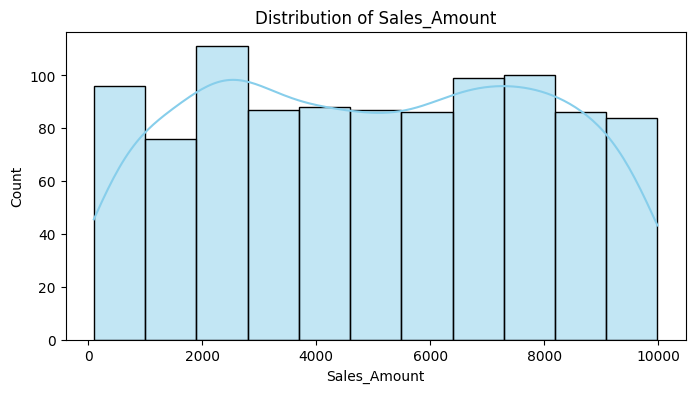

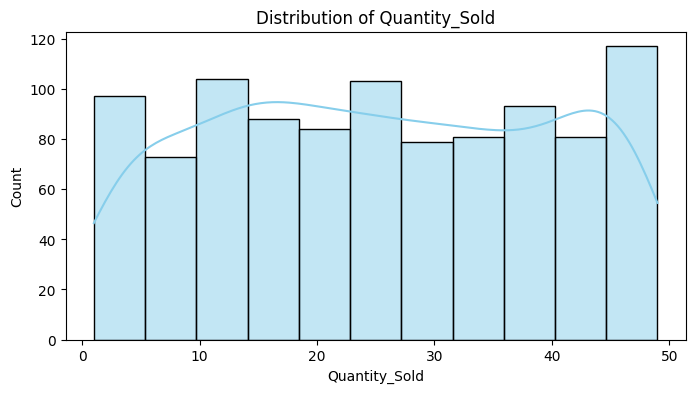

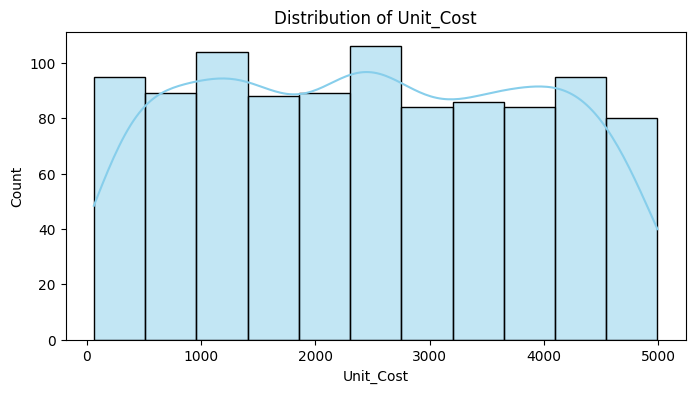

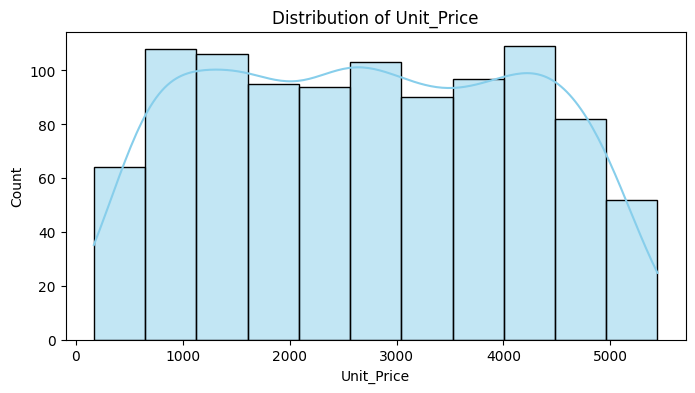

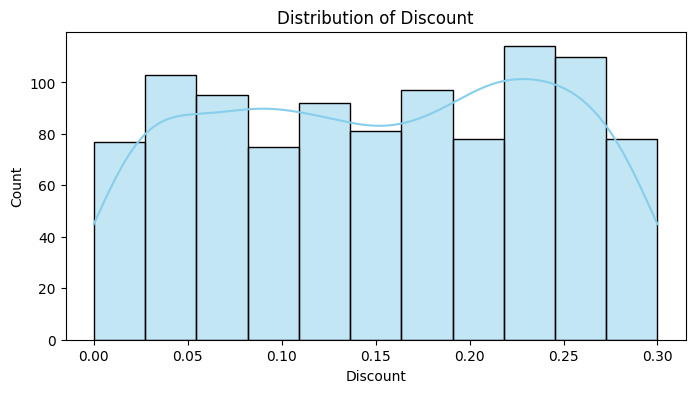

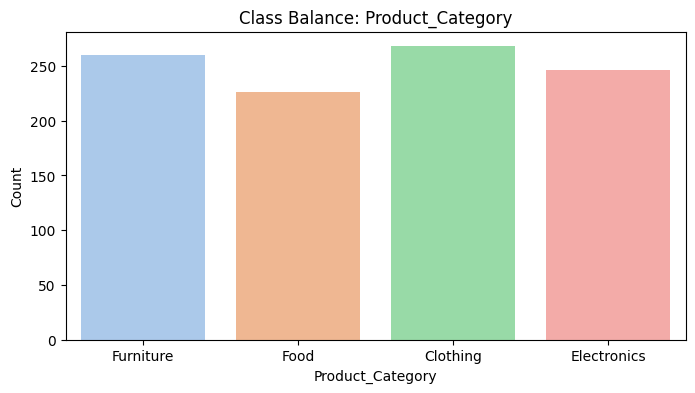

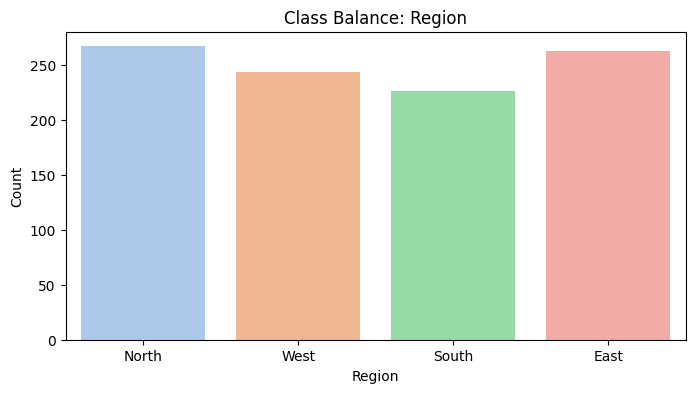

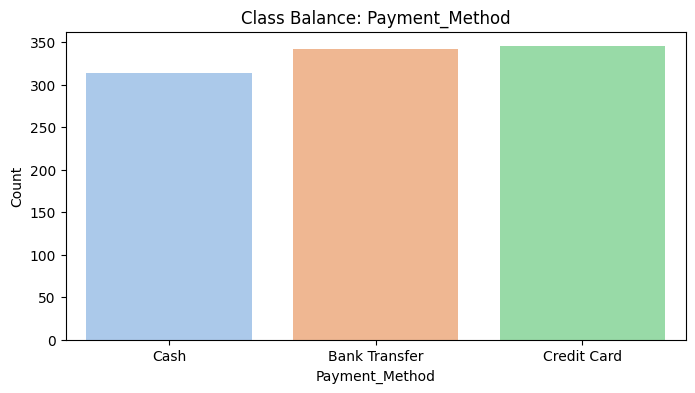

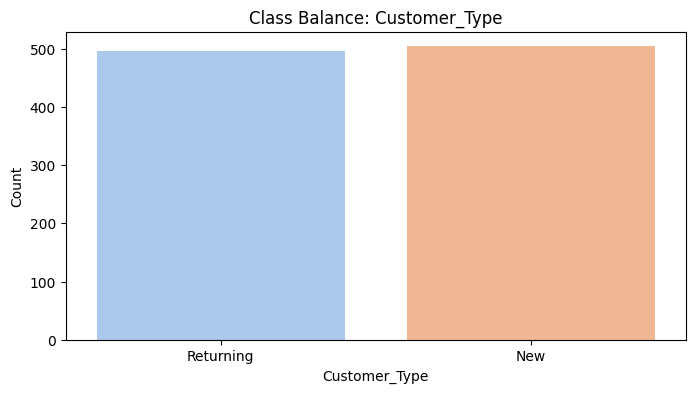

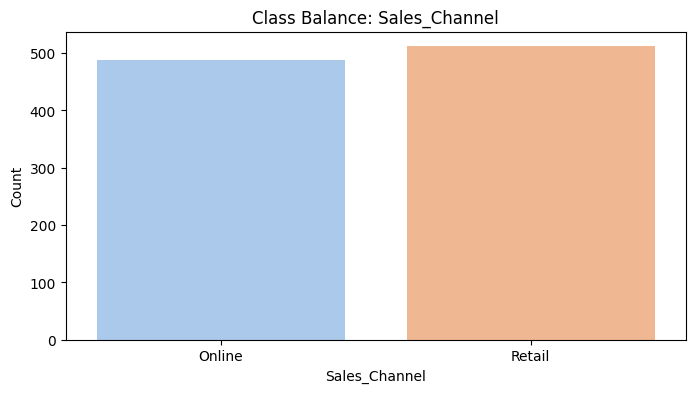

In [59]:
#Exploratory Data Analysis (EDA)
import matplotlib.pyplot as plt
import seaborn as sns
numeric_cols=['Sales_Amount', 'Quantity_Sold', 'Unit_Cost', 'Unit_Price', 'Discount']
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()
categorical_cols = ['Product_Category', 'Region', 'Payment_Method', 'Customer_Type', 'Sales_Channel']
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue=col, legend=False, palette='pastel')
    plt.title(f'Class Balance: {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

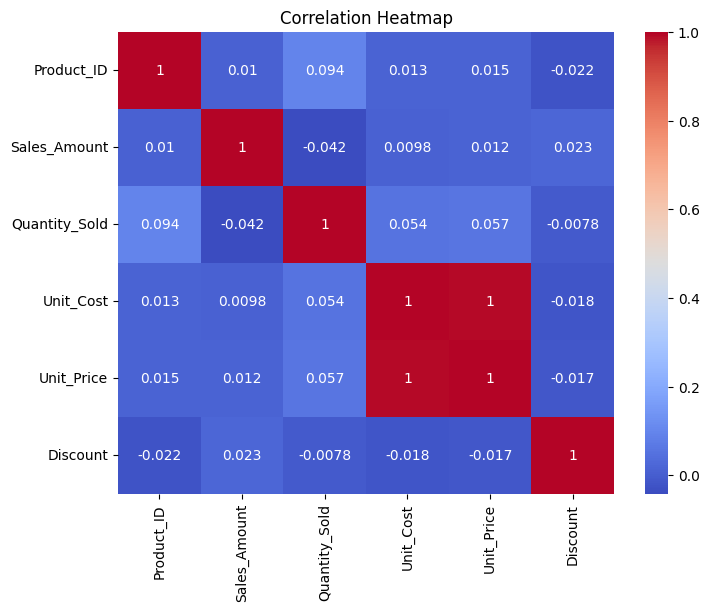

In [60]:
plt.figure(figsize=(8, 6))
correlation_matrix = df.select_dtypes(include=['number']).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [61]:
from sklearn.model_selection import train_test_split
cols_to_drop=['Product_ID', 'Sale_Date', 'Sales_Rep', 'Region_and_Sales_Rep']
ml_df = df.drop(columns=cols_to_drop)
categorical_cols=['Product_Category', 'Region', 'Payment_Method', 'Customer_Type', 'Sales_Channel']
ml_df=pd.get_dummies(ml_df, columns=categorical_cols, drop_first=True)
X=ml_df.drop(columns=['Sales_Amount'])
y=ml_df['Sales_Amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
display(X_train.head())

,Quantity_Sold,Unit_Cost,Unit_Price,Discount,Product_Category_Electronics,Product_Category_Food,Product_Category_Furniture,Region_North,Region_South,Region_West,Payment_Method_Cash,Payment_Method_Credit Card,Customer_Type_Returning,Sales_Channel_Retail
29,1,3290.89,3317.75,0.17,False,False,True,False,False,True,False,False,True,False
535,25,1330.62,1543.69,0.27,True,False,False,False,False,False,False,True,False,False
695,27,3624.97,3836.52,0.08,False,False,True,False,False,True,True,False,False,False
557,9,335.82,498.31,0.26,False,False,False,False,True,False,True,False,False,True
836,20,668.11,803.49,0.21,False,True,False,False,False,False,False,False,False,False


In [62]:
#Initialize and fit the RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Hyperparameter Justification:
#n_estimators=100: It offers a strong balance between model stability and computational efficiency for 800 samples.
#max_depth=10: Limiting the depth to 10 prevents the individual trees from growing too complex which helps prevent overfitting on our training dataset.
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Absolute Error (MAE): $2702.82
Root Mean Squared Error (RMSE): $3082.14
R-squared (R2) Score: -0.0279


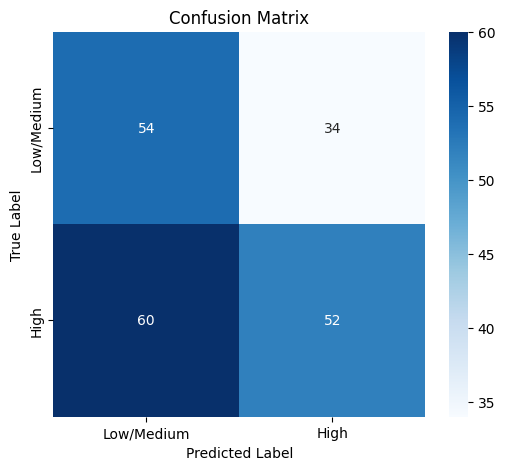

In [63]:
#Plot Confusion Matrix
cm = confusion_matrix(y_class_test, y_pred_class)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low/Medium', 'High'], yticklabels=['Low/Medium', 'High'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

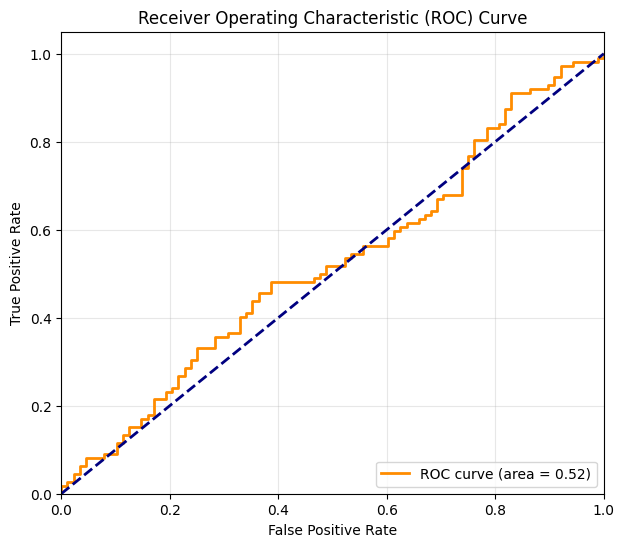

In [64]:
# Plot ROC Curve and AUC Score
fpr, tpr, thresholds = roc_curve(y_class_test, y_pred_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

/tmp/ipykernel_2156/2167818120.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


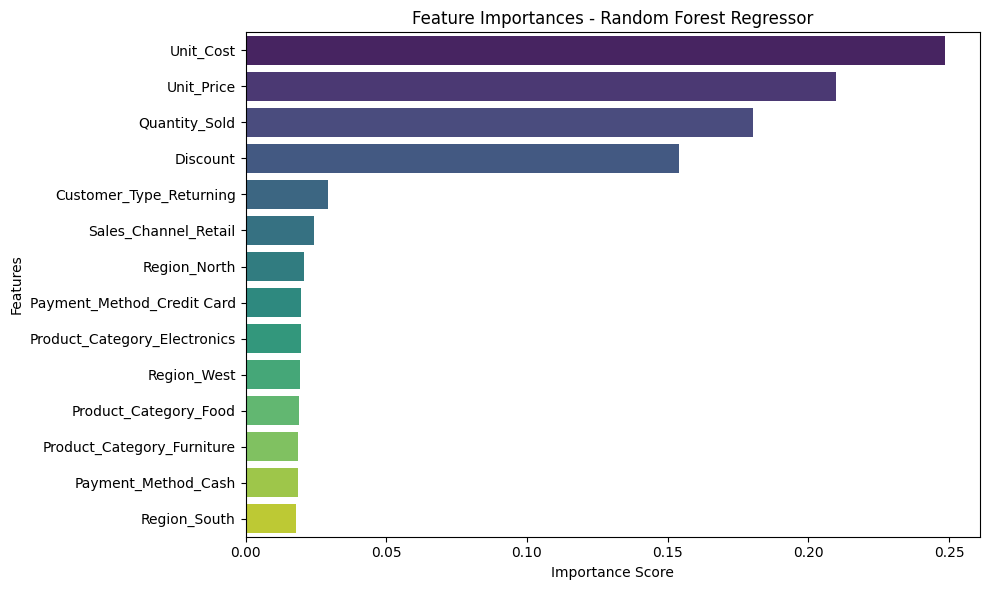

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
importances = rf_model.feature_importances_
features = X_train.columns
# Create a DataFrame for sorting and plotting
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)
# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importances - Random Forest Regressor')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [66]:
from sklearn.metrics import f1_score

# Calculate the F1-score
f1 = f1_score(y_class_test, y_pred_class)
print(f"Classification F1-Score: {f1:.4f}")

Classification F1-Score: 0.5253


In [67]:
from sklearn.metrics import precision_score, recall_score
#Precision and Recall
precision = precision_score(y_class_test, y_pred_class)
recall = recall_score(y_class_test, y_pred_class)
print(f"Classification Precision Score: {precision:.4f}")
print(f"Classification Recall Score:    {recall:.4f}")

Classification Precision Score: 0.6047
Classification Recall Score:    0.4643
